In [ ]:
import time
import torch
import numpy as np
from addict import Dict
import matplotlib.pyplot as plt

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 可视化
from utils.visualizer import plot_events_3d, plot_event_time2d, save_voxel_grid_video, plot_flow_field
from methods.affinegs.cmax import ContrastMaximizationLoss
from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities
# 评价指标
from utils.metrics import PIVmetric
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow

346.216 4.512 350.728
torch.Size([410697, 4])


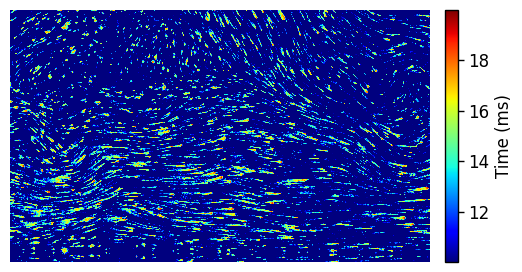

In [2]:
flow_index = 0
flow_names = ["ebiv","water"]

cases = [
    Dict(source_type="real", path="./data/real_old/ebiv_wallflow4_dense.h5"),
    Dict(source_type="evk5", path="./data/nn1.hdf5")
]

flow_cbar_cfgs = {
    0: dict(v_min=0.0, v_max=4.0, cbar_ticks=[0.0, 1.0, 2.0, 3.0, 4.0]),
    1: dict(v_min=0.0, v_max=2.0, cbar_ticks=[0.0, 0.5, 1.0, 1.5, 2.0]),
    # 1: dict(v_min=0.0, v_max=6.0, cbar_ticks=[0.0, 1.5, 3.0, 4.5, 6.0]),
}
flow_cbar_cfg = flow_cbar_cfgs[flow_index]
flow_font_size = 12

event_loader = EventManager(**cases[flow_index])
evts, _ = event_loader.load()
print(evts[:, 2].max()-evts[:, 2].min(), evts[:, 2].min(), evts[:, 2].max())

evts1 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 20)]).to("cuda")
print(evts1.shape)
plot_event_time2d(
    evts1,
    output_file=None,
    figsize=(5, 3),
    cbar_tick_size=flow_font_size,
    cbar_label_size=flow_font_size,
    image_rect=(0.02, 0.08, 0.84, 0.84),
    cbar_rect=(0.89, 0.08, 0.025, 0.84),
)
torch.cuda.empty_cache()

[AutoLR] lr_jacobian = 0.001 (manual)
开始训练 | 初始高斯数: 500
Iter 0000 | total=-6.636712 | data=-7.846930 | div=0.012102 | N=500
  [DensityCtrl] valid_blocks=576  localvar_mean=0.0014  cov_mean=0.8181  curv_mean=0.1056
  [Clone] block_candidates=74  selected=50  copied=1  random=49  radius=140.0
gaussian_candidates=17  selected=17  res_support_mean=0.0016  curv_support_mean=0.1420
  [Prune] opacity=9  geometry=59  nonfinite=0  total=68
  [{'clone', 'prune', 'split'}] Clone:50  Split:17  Prune:68  -> N=499
Iter 0050 | total=-25.022999 | data=-25.093563 | div=0.000706 | N=499
  [DensityCtrl] valid_blocks=576  localvar_mean=0.0016  cov_mean=0.9140  curv_mean=0.1293
  [Clone] block_candidates=31  selected=31  copied=31  random=0  radius=140.0
gaussian_candidates=14  selected=14  res_support_mean=0.0016  curv_support_mean=0.1566
  [Prune] opacity=10  geometry=54  nonfinite=0  total=64
  [{'clone', 'prune', 'split'}] Clone:31  Split:14  Prune:64  -> N=480
Iter 0100 | total=-27.990627 | data=-28.0

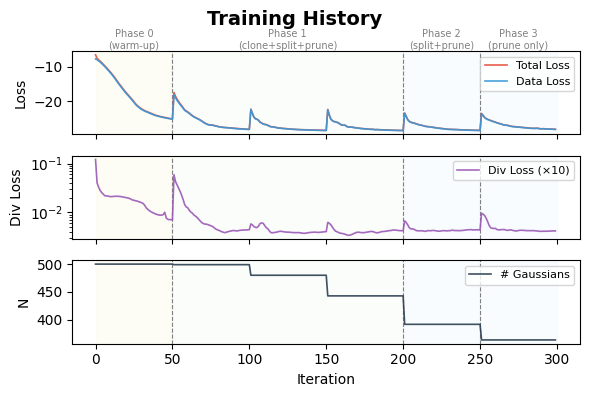

验证推理中（训练分辨率 720×1280 → 输出分辨率 720×1280）...
验证推理完成
运行时间: 2.621434 秒


In [3]:
start = time.time()
cfg = GaussianFlowConfig(H=720, W = 1280, init_n=500, w_div=100, verbose=True, tile_size=80, 
                         init_scale_h=50.0, init_scale_w=35.0,
                         cmax_sigma=0.6, cmax_kernel_size=5, lr_j=0.001, 
                         enable_jacobian=False, jacobian_mode="full", 
                         iterations=300, residual_block_size=40, prune_opacity_thresh=0.1,
                         log_scale_min=np.log(8), phase=[50, 200, 250])

results = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)

end = time.time()     # 记录结束时间
print(f"运行时间: {end - start:.6f} 秒")
torch.cuda.empty_cache()

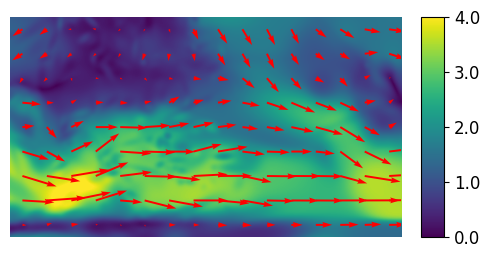

In [4]:
save_gs_result = False

gs_method_name = "AffineGS" if cfg.enable_jacobian else "ConstGS"
gs_output_file = f"./output/EXP3/{gs_method_name}-{flow_names[flow_index]}.pdf" if save_gs_result else None

plot_flow_field(results.flow[0], results.flow[1], output_file=gs_output_file,
                v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
                cbar_ticks=flow_cbar_cfg["cbar_ticks"], 
                colorbar_flag=True, step=1, quiver_step=80, scale=None, 
                slFlag=False, figsize=(5, 3), cbar_tick_size=flow_font_size)
if save_gs_result:
    print(f"saved: {gs_output_file}")

In [5]:
estimators = [ilk_vg, of_vg, inr_est, inr_vg]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG"]

# 0: ILK_VG, 1: OF_VG, 2: INR_EST, 3: INR_VG
method_index = 1
estimator_H = 720
estimator_W = 1280

def compute_estimator_by_index(method_index, events, H=720, W=1280):
    if method_index < 0 or method_index >= len(estimators):
        raise IndexError(f"method_index must be in [0, {len(estimators) - 1}], got {method_index}")

    estimator = estimators[method_index]
    method_name = method_names[method_index]

    start = time.time()
    v_h, v_w, div, vor = estimator(events, H=H, W=W)
    elapsed = time.time() - start
    torch.cuda.empty_cache()

    print(f"{method_name}: {elapsed:.4f} s")
    return Dict(
        method_index=method_index,
        method_name=method_name,
        v_h=v_h,
        v_w=v_w,
        div=div,
        vor=vor,
        elapsed=elapsed,
        H=H,
        W=W,
    )


method_result = compute_estimator_by_index(method_index, evts1, H=estimator_H, W=estimator_W)

OF_VG: 1.4999 s


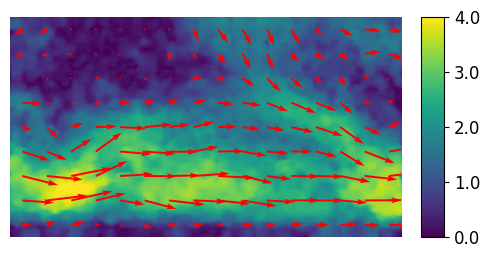

In [6]:
save_method_result = False

method_output_file = f"./output/EXP3/{method_result.method_name}-{flow_names[flow_index]}.pdf" if save_method_result else None

plot_flow_field(
    method_result.v_h, method_result.v_w, None, None,
    output_file=method_output_file,
    magFlag=True, slFlag=False, colorbar_flag=True,
    step=1, quiver_step=80,
    v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
    scale=None, figsize=(5, 3),
    cbar_ticks=flow_cbar_cfg["cbar_ticks"], cbar_tick_size=flow_font_size,
)
if save_method_result:
    print(f"saved: {method_output_file}")